# 📉 Predicción de fuga de clientes (Churn) en Telecomunicaciones
### Árboles de decisión interpretables + optimización del beneficio de una campaña de retención

**Autor:** _Cristobal Rojas_ · **Herramientas:** Python, pandas, scikit-learn, matplotlib, seaborn

---

## 🎯 Contexto de negocio

Una compañía de telecomunicaciones pierde cerca de **1 de cada 4 clientes**. Captar un cliente nuevo cuesta varias veces más que retener uno existente, por lo que el área comercial quiere:

1. **Predecir** qué clientes tienen alta probabilidad de darse de baja (*churn*).
2. **Entender** qué factores explican la fuga, con reglas que el equipo comercial pueda leer.
3. **Decidir** a cuántos clientes contactar con una oferta de retención para **maximizar el beneficio**, no sólo la exactitud del modelo.

**Dataset:** [Telco Customer Churn — Kaggle (IBM Sample Data)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) · 7.043 clientes · 21 variables (servicios contratados, tipo de contrato, facturación y antigüedad).

## 🧭 Hoja de ruta
| # | Etapa | Qué aporta |
|---|---|---|
| 1 | Carga y auditoría de datos | Detección de **valores faltantes ocultos** que `isna()` no ve |
| 2 | Análisis exploratorio (EDA) | Tasas de fuga por segmento |
| 3 | Ingeniería de variables | Variables de negocio nuevas |
| 4 | Árbol base vs. árbol ajustado | Diagnóstico de sobreajuste + `GridSearchCV` |
| 5 | Benchmark de modelos | Regresión logística, Random Forest, Gradient Boosting |
| 6 | Interpretabilidad | Reglas del árbol + importancia por permutación |
| 7 | **Del modelo al dinero** | Umbral óptimo por **curva de beneficio**, curva de ganancia acumulada |
| 8 | Segmentación de riesgo | Lista accionable para el equipo comercial |

In [1]:
# ==== Importaciones ====
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     cross_val_predict)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42
IMG = Path("../images"); IMG.mkdir(parents=True, exist_ok=True)
REP = Path("../reports"); REP.mkdir(parents=True, exist_ok=True)

# ==== Estilo visual consistente para todo el proyecto ====
AZUL, NARANJA, VERDE, VIOLETA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#8a8984"
TINTA, TINTA2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8, "legend.frameon": False,
})

def es(x, dec=0):
    """Formato numérico chileno: 1.234,5"""
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

def guardar(nombre):
    plt.savefig(IMG / f"{nombre}.png", facecolor="white")
    plt.show()

## 1. Carga y auditoría de datos

Descarga el archivo `WA_Fn-UseC_-Telco-Customer-Churn.csv` desde Kaggle y ubícalo en la carpeta `data/`. Si no está, el notebook lo lee directamente desde el repositorio público de IBM (misma fuente original del dataset).

In [2]:
RUTA_LOCAL = Path("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
URL_RESPALDO = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
                "master/data/Telco-Customer-Churn.csv")

df_original = pd.read_csv(RUTA_LOCAL if RUTA_LOCAL.exists() else URL_RESPALDO)
print(f"Filas: {df_original.shape[0]:,} | Columnas: {df_original.shape[1]}")
df_original.head()

Filas: 7,043 | Columnas: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### 1.1 Valores faltantes ocultos

`isna()` reporta **cero** valores faltantes, pero `TotalCharges` figura como texto (`object`) cuando debería ser numérica. Eso suele indicar celdas vacías escritas como espacios en blanco. Es una trampa típica que un simple `dropna()` no detecta.

In [4]:
print("Faltantes según isna():", int(df_original.isna().sum().sum()))

df = df_original.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
ocultos = df[df["TotalCharges"].isna()]
print(f"Faltantes ocultos en TotalCharges: {len(ocultos)}")
ocultos[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Faltantes según isna(): 0
Faltantes ocultos en TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


**Diagnóstico:** los 11 registros tienen `tenure = 0`: son clientes recién incorporados que **todavía no han recibido su primera factura**. No son errores, así que en vez de eliminarlos se imputa `TotalCharges = 0`, lo que es coherente con el negocio.

In [5]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns="customerID")
print("Duplicados:", df.duplicated().sum(), "| Faltantes:", int(df.isna().sum().sum()), "| Shape:", df.shape)

Duplicados: 22 | Faltantes: 0 | Shape: (7043, 20)


Los 22 "duplicados" aparecen sólo después de quitar `customerID`: son **clientes distintos con el mismo perfil** (típicamente clientes nuevos con plan básico), así que se conservan.

## 2. Análisis exploratorio (EDA)

Churn
No     5174
Yes    1869
Name: count, dtype: int64 
Tasa de fuga: 26.5%


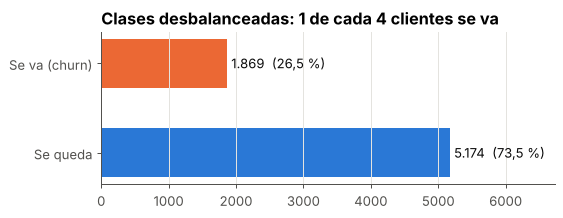

In [6]:
tasa = df["Churn"].value_counts()
print(tasa, f"\nTasa de fuga: {tasa['Yes']/len(df):.1%}")

fig, ax = plt.subplots(figsize=(6.5, 2.2))
ax.barh(["Se queda", "Se va (churn)"], [tasa["No"], tasa["Yes"]], color=[AZUL, NARANJA], height=0.55)
for i, v in enumerate([tasa["No"], tasa["Yes"]]):
    ax.text(v + 60, i, f"{es(v)}  ({es(100*v/len(df), 1)} %)", va="center", color=TINTA)
ax.set_xlim(0, tasa.max() * 1.3); ax.grid(axis="y", visible=False)
ax.set_title("Clases desbalanceadas: 1 de cada 4 clientes se va")
guardar("01_balance_clases")

A diferencia de un dataset balanceado, aquí la *accuracy* engaña: un modelo que diga siempre "se queda" acierta 73 % sin aprender nada. Por eso priorizaremos **recall, F1, ROC-AUC y, sobre todo, beneficio económico**.

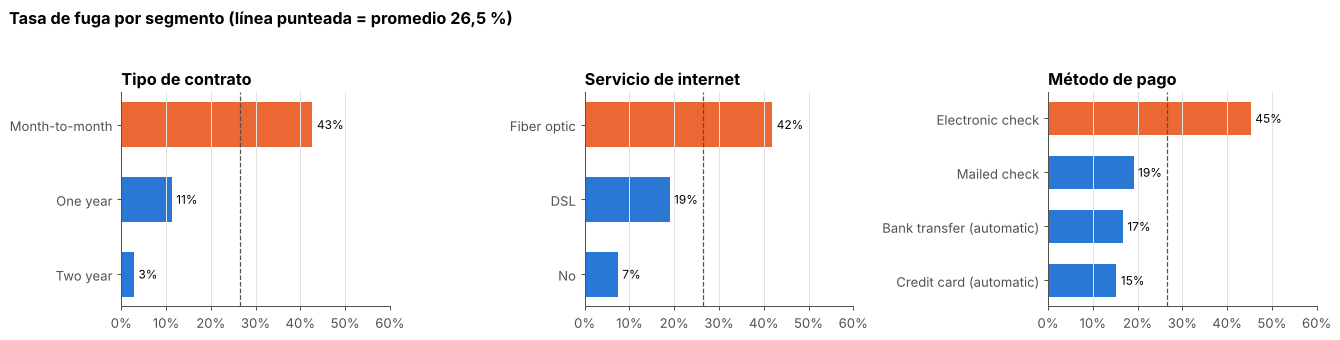

In [7]:
def tasa_por(col):
    return (df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean())
              .sort_values(ascending=True))

media = (df["Churn"] == "Yes").mean()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, titulo in zip(axes, ["Contract", "InternetService", "PaymentMethod"],
                           ["Tipo de contrato", "Servicio de internet", "Método de pago"]):
    t = tasa_por(col)
    colores = [NARANJA if v > media else AZUL for v in t.values]
    ax.barh(t.index, t.values, color=colores, height=0.6)
    ax.axvline(media, color=TINTA2, ls="--", lw=1)
    for i, v in enumerate(t.values):
        ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9.5)
    ax.set_xlim(0, 0.6); ax.set_title(titulo); ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
fig.suptitle("Tasa de fuga por segmento (línea punteada = promedio 26,5 %)", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.04)
plt.tight_layout()
guardar("02_churn_por_segmento")

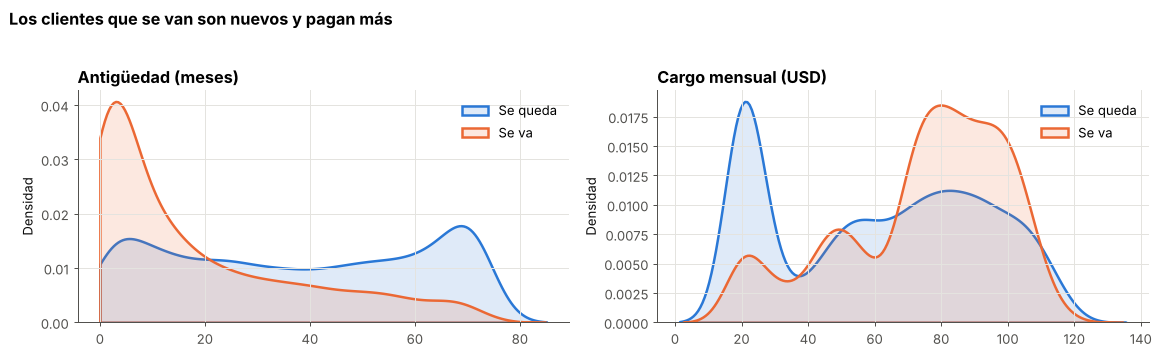

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, titulo in zip(axes, ["tenure", "MonthlyCharges"],
                           ["Antigüedad (meses)", "Cargo mensual (USD)"]):
    for etiqueta, color, nombre in [("No", AZUL, "Se queda"), ("Yes", NARANJA, "Se va")]:
        sns.kdeplot(df.loc[df["Churn"] == etiqueta, col], ax=ax, color=color, lw=2,
                    fill=True, alpha=0.15, label=nombre, clip=(0, None))
    ax.set_title(titulo); ax.set_xlabel(""); ax.set_ylabel("Densidad"); ax.legend()
fig.suptitle("Los clientes que se van son nuevos y pagan más", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
guardar("03_distribuciones")

**Hallazgos del EDA**
- El **contrato mes a mes** concentra la fuga (≈ 43 %) frente a 11 % en contratos de 1 año y 3 % en 2 años.
- Los clientes con **fibra óptica** se van más (≈ 42 %): pagan más y probablemente comparan precios.
- El pago con **cheque electrónico** presenta ≈ 45 % de fuga.
- El riesgo se concentra en los **primeros meses** de vida del cliente.

## 3. Ingeniería de variables

Además de codificar las variables, se crean tres variables de negocio:
- `n_servicios`: número de servicios adicionales contratados (más servicios → mayor costo de cambio).
- `cargo_promedio`: gasto histórico medio por mes (`TotalCharges / tenure`).
- `cliente_nuevo`: 1 si la antigüedad es ≤ 6 meses.

`Contract` es **ordinal** (mes a mes < 1 año < 2 años), por lo que se codifica como 0/1/2. El resto de categóricas va con *one-hot encoding*.

In [9]:
servicios = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
             "StreamingTV", "StreamingMovies", "MultipleLines"]
datos = df.copy()
datos["n_servicios"] = (datos[servicios] == "Yes").sum(axis=1)
datos["cargo_promedio"] = np.where(datos["tenure"] > 0, datos["TotalCharges"] / datos["tenure"],
                                   datos["MonthlyCharges"])
datos["cliente_nuevo"] = (datos["tenure"] <= 6).astype(int)

datos["Contract"] = datos["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})
datos["Churn"] = (datos["Churn"] == "Yes").astype(int)
binarias = ["gender", "Partner", "Dependents", "PhoneService", "PaperlessBilling"]
for c in binarias:
    datos[c] = (datos[c].isin(["Yes", "Female"])).astype(int)
datos = datos.rename(columns={"gender": "es_mujer"})
datos = pd.get_dummies(datos, drop_first=True, dtype=int)

X = datos.drop(columns="Churn")
y = datos["Churn"]
print("Matriz de diseño:", X.shape)

Matriz de diseño: (7043, 32)


### División entrenamiento / prueba
75 % / 25 %, **estratificada** para conservar la proporción de fuga en ambos conjuntos. El conjunto de prueba **no se toca** hasta la evaluación final.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Churn train: {y_train.mean():.1%} | Churn test: {y_test.mean():.1%}")

Train: (5282, 32) | Test: (1761, 32)
Churn train: 26.5% | Churn test: 26.5%


## 4. Árbol de decisión: base vs. ajustado
### 4.1 Árbol base (sin restricciones)

In [11]:
arbol_base = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)

def metricas(modelo, X_, y_, umbral=0.5):
    p = modelo.predict_proba(X_)[:, 1]
    pred = (p >= umbral).astype(int)
    return {"Accuracy": accuracy_score(y_, pred), "Precision": precision_score(y_, pred),
            "Recall": recall_score(y_, pred), "F1": f1_score(y_, pred),
            "ROC-AUC": roc_auc_score(y_, p), "PR-AUC": average_precision_score(y_, p)}

diag = pd.DataFrame({"Entrenamiento": metricas(arbol_base, X_train, y_train),
                     "Prueba": metricas(arbol_base, X_test, y_test)}).T.round(3)
print(f"Profundidad: {arbol_base.get_depth()} | Hojas: {arbol_base.get_n_leaves()}")
diag

Profundidad: 25 | Hojas: 972


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Entrenamiento,0.998,0.994,0.999,0.996,1.000,1.000
Prueba,0.746,0.522,0.514,0.518,0.672,0.398


**Sobreajuste evidente:** el árbol sin límites crece hasta 25 niveles y casi 1.000 hojas, memoriza el entrenamiento (99,8 % de exactitud) y en prueba cae a 74,6 %, apenas sobre el 73,5 % de predecir siempre "se queda". Su ROC-AUC de 0,67 confirma que generaliza mal.

### 4.2 Ajuste de hiperparámetros con `GridSearchCV`
Se buscan simultáneamente la profundidad, el tamaño mínimo de hoja, el criterio de división y **`class_weight`** (para compensar el desbalance) con validación cruzada estratificada de 5 particiones.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grilla = {"max_depth": [2, 3, 4, 5, 6, 7, 8, 10, 12],
          "min_samples_leaf": [1, 5, 10, 20, 50, 100],
          "criterion": ["gini", "entropy"],
          "class_weight": [None, "balanced"]}
busqueda = GridSearchCV(DecisionTreeClassifier(random_state=SEED), grilla,
                        scoring=["f1", "roc_auc", "recall", "precision"], refit="f1",
                        cv=cv, n_jobs=-1)
busqueda.fit(X_train, y_train)
arbol = busqueda.best_estimator_
print("Mejores hiperparámetros:", busqueda.best_params_)
print(f"F1 medio en validación cruzada: {busqueda.best_score_:.3f}")
print(f"Profundidad: {arbol.get_depth()} | Hojas: {arbol.get_n_leaves()}")

Mejores hiperparámetros: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 20}
F1 medio en validación cruzada: 0.619
Profundidad: 5 | Hojas: 31


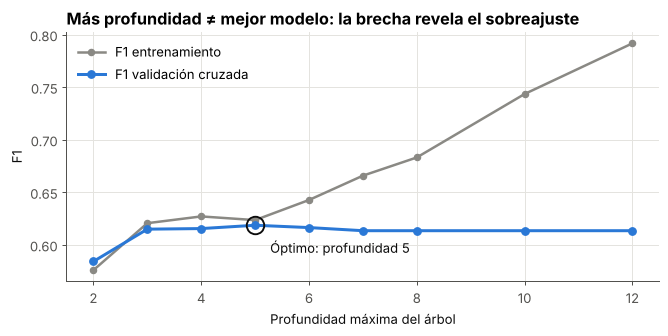

In [13]:
# Cómo cambia el F1 de validación con la profundidad (mejor configuración por profundidad)
res = pd.DataFrame(busqueda.cv_results_)
res["max_depth"] = res["param_max_depth"].astype(int)
curva = res.groupby("max_depth")[["mean_test_f1", "mean_test_roc_auc"]].max()
tr_f1 = [f1_score(y_train, DecisionTreeClassifier(max_depth=d, random_state=SEED,
         class_weight=busqueda.best_params_["class_weight"],
         criterion=busqueda.best_params_["criterion"]).fit(X_train, y_train).predict(X_train))
         for d in curva.index]

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(curva.index, tr_f1, "-o", color=GRIS, lw=2, ms=5, label="F1 entrenamiento")
ax.plot(curva.index, curva["mean_test_f1"], "-o", color=AZUL, lw=2.4, ms=6, label="F1 validación cruzada")
d = busqueda.best_params_["max_depth"]
ax.plot(d, curva.loc[d, "mean_test_f1"], "o", ms=14, mfc="none", mec=TINTA, mew=1.5)
ax.annotate(f"Óptimo: profundidad {d}", (d, curva.loc[d, "mean_test_f1"]),
            xytext=(12, -22), textcoords="offset points", color=TINTA)
ax.set_xlabel("Profundidad máxima del árbol"); ax.set_ylabel("F1")
ax.set_title("Más profundidad ≠ mejor modelo: la brecha revela el sobreajuste"); ax.legend()
guardar("04_curva_complejidad")

## 5. Benchmark: ¿cuánto rendimiento se sacrifica por interpretabilidad?
Se compara el árbol ajustado con una regresión logística (línea base lineal), un Random Forest y un Gradient Boosting, todos evaluados en el **mismo conjunto de prueba**.

In [14]:
modelos = {
    "Árbol base": arbol_base,
    "Árbol ajustado": arbol,
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=SEED)).fit(X_train, y_train),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=10,
        class_weight="balanced", n_jobs=-1, random_state=SEED).fit(X_train, y_train),
    "Gradient Boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4,
        max_iter=300, class_weight="balanced", random_state=SEED).fit(X_train, y_train),
}
tabla = pd.DataFrame({n: metricas(m, X_test, y_test) for n, m in modelos.items()}).T.round(3)
tabla.to_csv(REP / "comparacion_modelos.csv")
tabla.sort_values("ROC-AUC", ascending=False)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Regresión logística,0.748,0.516,0.803,0.628,0.849,0.657
Random Forest,0.770,0.545,0.801,0.649,0.847,0.652
Gradient Boosting,0.758,0.529,0.769,0.627,0.837,0.637
Árbol ajustado,0.726,0.490,0.822,0.614,0.834,0.619
Árbol base,0.746,0.522,0.514,0.518,0.672,0.398


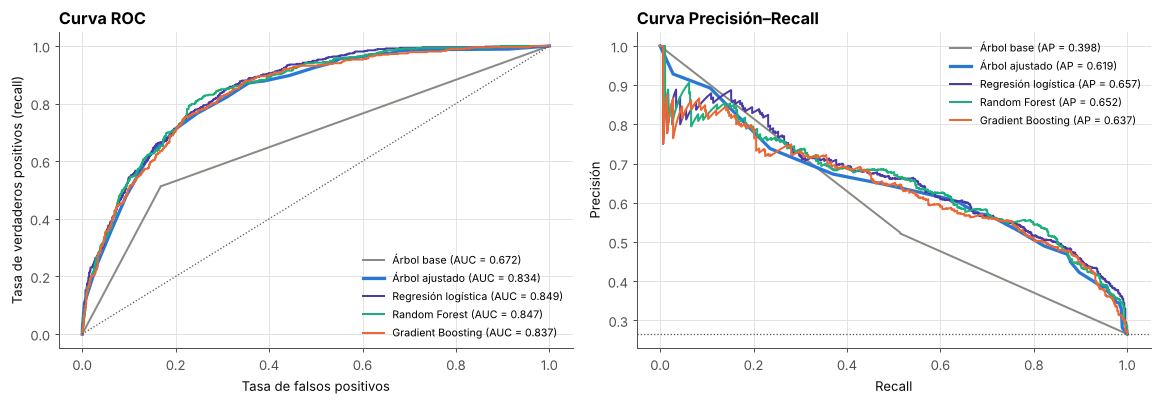

In [15]:
colores = {"Árbol base": GRIS, "Árbol ajustado": AZUL, "Regresión logística": VIOLETA,
           "Random Forest": VERDE, "Gradient Boosting": NARANJA}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6))
for n, m in modelos.items():
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    pr, rc, _ = precision_recall_curve(y_test, p)
    lw = 2.6 if n == "Árbol ajustado" else 1.6
    a1.plot(fpr, tpr, color=colores[n], lw=lw, label=f"{n} (AUC = {roc_auc_score(y_test, p):.3f})")
    a2.plot(rc, pr, color=colores[n], lw=lw, label=f"{n} (AP = {average_precision_score(y_test, p):.3f})")
a1.plot([0, 1], [0, 1], ":", color=TINTA2, lw=1)
a1.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos (recall)")
a1.set_title("Curva ROC"); a1.legend(fontsize=8.5, loc="lower right")
a2.axhline(y_test.mean(), ls=":", color=TINTA2, lw=1)
a2.set(xlabel="Recall", ylabel="Precisión"); a2.set_title("Curva Precisión–Recall")
a2.legend(fontsize=8.5, loc="upper right")
plt.tight_layout()
guardar("05_roc_pr_modelos")

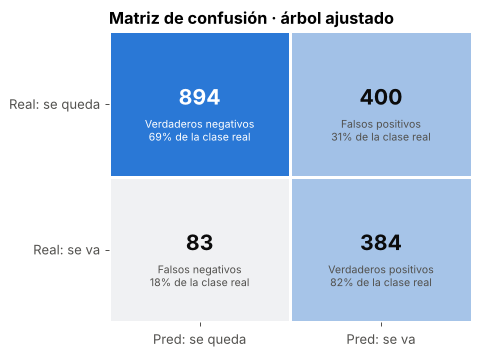

In [16]:
umbral_defecto = 0.5
pred = (arbol.predict_proba(X_test)[:, 1] >= umbral_defecto).astype(int)
cm = confusion_matrix(y_test, pred)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
sns.heatmap(cm, annot=False, cmap=sns.light_palette(AZUL, as_cmap=True), cbar=False,
            linewidths=2, linecolor="white", ax=ax)
etiquetas = [["Verdaderos negativos", "Falsos positivos"], ["Falsos negativos", "Verdaderos positivos"]]
for i in range(2):
    for j in range(2):
        ax.text(j + 0.5, i + 0.45, f"{cm[i, j]:,}", ha="center", va="center", fontsize=17,
                fontweight="bold", color="white" if cm[i, j] > cm.max() * 0.6 else TINTA)
        ax.text(j + 0.5, i + 0.68, f"{etiquetas[i][j]}\n{cm[i, j]/cm[i].sum():.0%} de la clase real",
                ha="center", va="center", fontsize=8.5,
                color="white" if cm[i, j] > cm.max() * 0.6 else TINTA2)
ax.set_xticklabels(["Pred: se queda", "Pred: se va"]); ax.set_yticklabels(["Real: se queda", "Real: se va"], rotation=0)
ax.set_title("Matriz de confusión · árbol ajustado"); ax.grid(False)
guardar("06_matriz_confusion")

## 6. Interpretabilidad
### 6.1 Las reglas que aprendió el árbol

|--- Contract <= 0.50
|   |--- InternetService_Fiber optic <= 0.50
|   |   |--- tenure <= 5.50
|   |   |   |--- OnlineSecurity_No internet service <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- OnlineSecurity_No internet service >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- tenure >  5.50
|   |   |   |--- MonthlyCharges <= 25.38
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- MonthlyCharges >  25.38
|   |   |   |   |--- truncated branch of depth 2
|   |--- InternetService_Fiber optic >  0.50
|   |   |--- tenure <= 15.50
|   |   |   |--- TotalCharges <= 120.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- TotalCharges >  120.00
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- tenure >  15.50
|   |   |   |--- PaymentMethod_Electronic check <= 0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- PaymentMethod_Electronic check >  0.50
|   |   |   |   |--- truncated branch

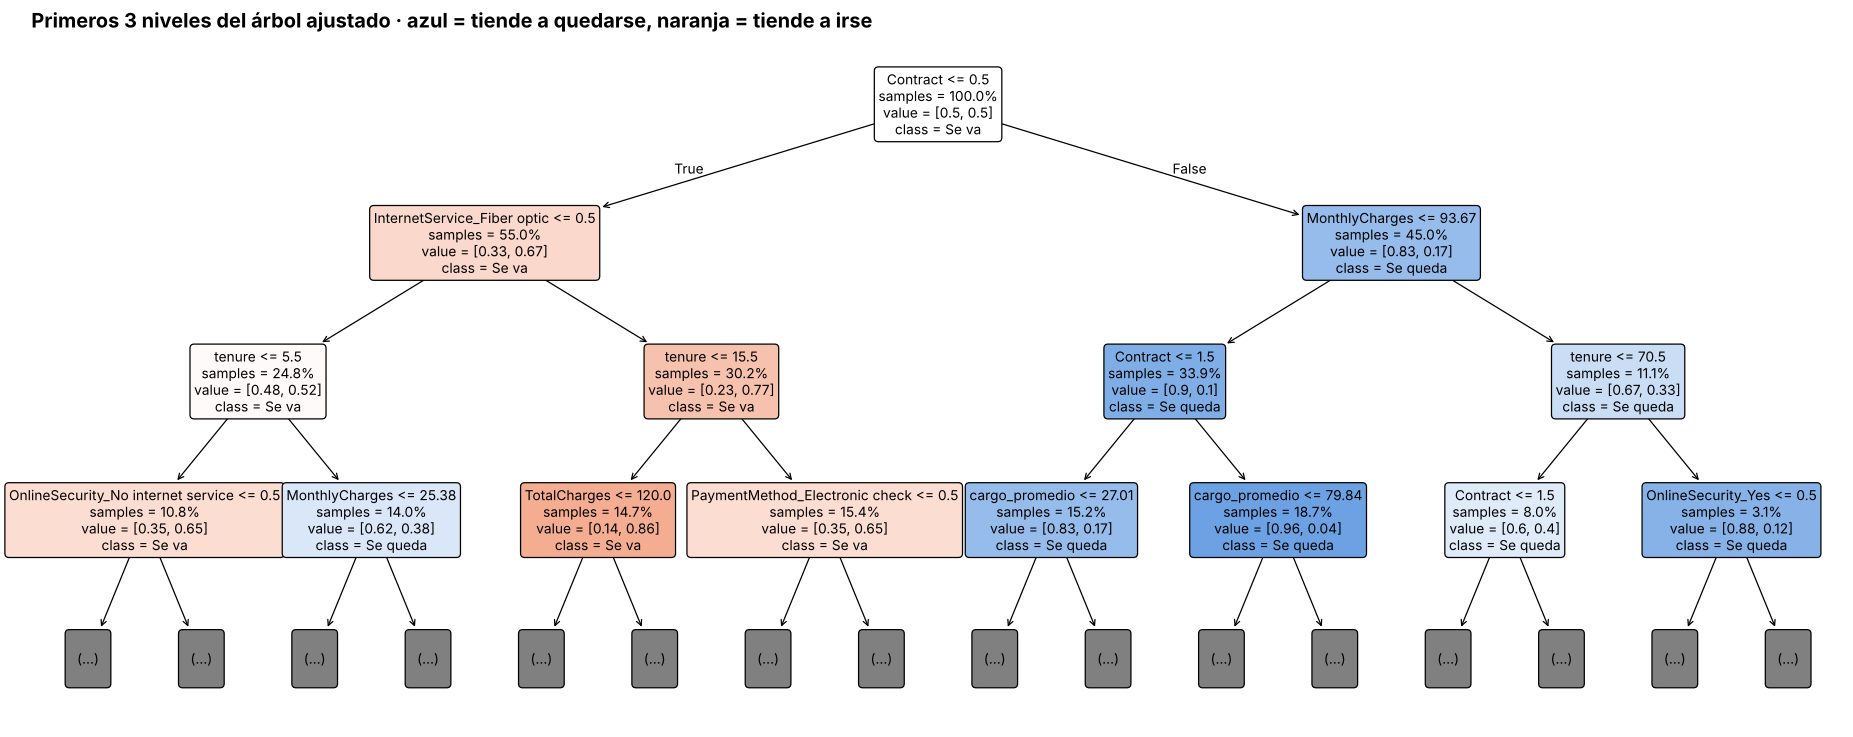

In [17]:
import re
from matplotlib.colors import to_rgb
fig, ax = plt.subplots(figsize=(26, 10))
nodos = plot_tree(arbol, max_depth=3, feature_names=X.columns, class_names=["Se queda", "Se va"],
                  filled=True, rounded=True, impurity=False, proportion=True, precision=2,
                  fontsize=11, ax=ax)
# Recolorear nodos con la paleta del proyecto: azul = se queda, naranja = se va
for t in nodos:
    m = re.search(r"value = \[([\d.]+), ([\d.]+)\]", t.get_text())
    if m and t.get_bbox_patch() is not None:
        p_va = float(m.group(2))
        base = np.array(to_rgb(NARANJA if p_va >= 0.5 else AZUL))
        intensidad = abs(p_va - 0.5) * 2
        t.get_bbox_patch().set_facecolor(1 - intensidad * 0.75 * (1 - base))
ax.set_title("Primeros 3 niveles del árbol ajustado · azul = tiende a quedarse, naranja = tiende a irse",
             fontsize=16)
guardar("07_arbol_decision")

print(export_text(arbol, feature_names=list(X.columns), max_depth=3))

### 6.2 Importancia de variables: Gini vs. permutación
La importancia de Gini (la que entrega `feature_importances_`) está sesgada hacia variables continuas con muchos cortes posibles. La **importancia por permutación** mide cuánto cae el ROC-AUC en prueba al desordenar cada variable, y es la medida más honesta.

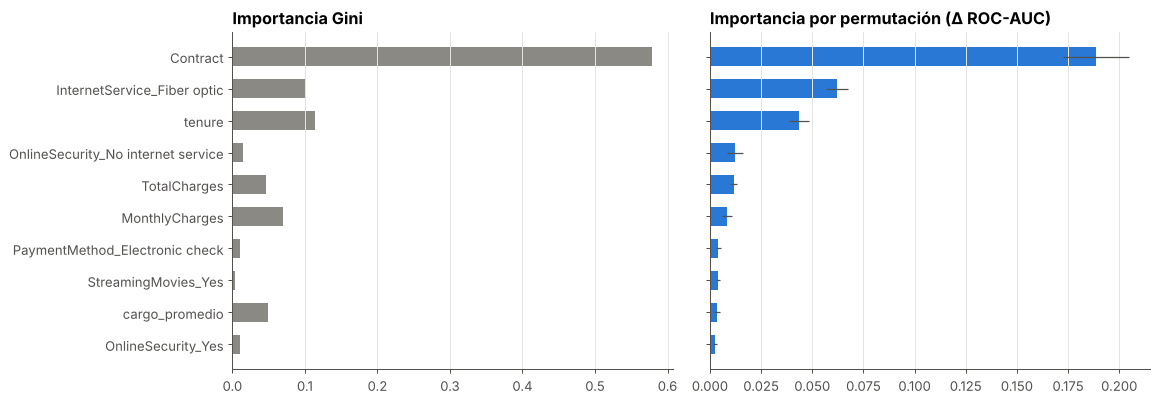

,Gini,Permutación,std
Contract,0.5785,0.1887,0.0163
InternetService_Fiber optic,0.1010,0.0621,0.0052
tenure,0.1135,0.0436,0.0051
OnlineSecurity_No internet service,0.0145,0.0122,0.0040
TotalCharges,0.0458,0.0116,0.0016
MonthlyCharges,0.0702,0.0084,0.0024
PaymentMethod_Electronic check,0.0108,0.0041,0.0012
StreamingMovies_Yes,0.0033,0.0038,0.0010
cargo_promedio,0.0492,0.0035,0.0014
OnlineSecurity_Yes,0.0106,0.0025,0.0008


In [18]:
perm = permutation_importance(arbol, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"Gini": arbol.feature_importances_, "Permutación": perm.importances_mean,
                    "std": perm.importances_std}, index=X.columns)
top = imp.sort_values("Permutación", ascending=False).head(10).iloc[::-1]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
a1.barh(top.index, top["Gini"], color=GRIS, height=0.6); a1.set_title("Importancia Gini")
a2.barh(top.index, top["Permutación"], xerr=top["std"], color=AZUL, height=0.6,
        error_kw=dict(ecolor=TINTA2, lw=1)); a2.set_title("Importancia por permutación (Δ ROC-AUC)")
for a in (a1, a2): a.grid(axis="y", visible=False)
plt.tight_layout()
guardar("08_importancia_variables")
imp.sort_values("Permutación", ascending=False).head(10).round(4)

## 7. 💰 Del modelo al dinero: ¿a quién conviene llamar?

Un umbral de 0,5 es arbitrario. Lo que importa al negocio es **cuánto dinero deja la campaña de retención**. Se define un modelo económico simple (supuestos editables):

| Supuesto | Valor | Interpretación |
|---|---|---|
| `COSTO_OFERTA` | USD 50 | Costo de contactar y ofrecer un beneficio a un cliente |
| `TASA_EXITO` | 35 % | De los clientes que iban a irse y reciben la oferta, cuántos se quedan |
| `MESES_RETENIDOS` | 12 | Meses de ingreso que se conservan si el cliente se queda |

$$\text{Beneficio}(u) = \sum_{i\,\in\,VP(u)} \text{TASA\_EXITO}\cdot \text{MESES}\cdot \text{Cargo}_i \;-\; \text{COSTO\_OFERTA}\cdot\big(VP(u)+FP(u)\big)$$

El umbral $u$ se elige con predicciones **fuera de muestra** del conjunto de entrenamiento (`cross_val_predict`) y luego se valida en prueba, para no hacer trampa con los datos de evaluación.

Umbral óptimo (elegido en entrenamiento): 0.33
Beneficio en prueba → contactar a todos: USD 56.075 | umbral 0,5: USD 81.145 | umbral óptimo: USD 86.313
Clientes contactados con el umbral óptimo: 52%


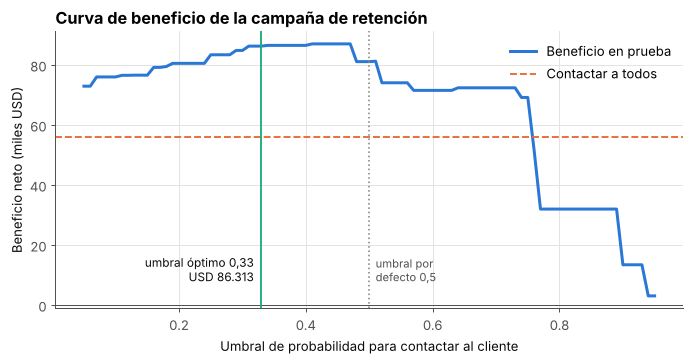

In [19]:
COSTO_OFERTA, TASA_EXITO, MESES_RETENIDOS = 50, 0.35, 12

def beneficio(y_real, prob, cargo, u):
    contactar = prob >= u
    vp = contactar & (y_real == 1)
    return (TASA_EXITO * MESES_RETENIDOS * cargo[vp]).sum() - COSTO_OFERTA * contactar.sum()

umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)
prob_oof = cross_val_predict(arbol, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
cargo_tr, cargo_te = X_train["MonthlyCharges"].values, X_test["MonthlyCharges"].values
b_oof = np.array([beneficio(y_train.values, prob_oof, cargo_tr, u) for u in umbrales])
u_opt = umbrales[b_oof.argmax()]

prob_te = arbol.predict_proba(X_test)[:, 1]
b_te = np.array([beneficio(y_test.values, prob_te, cargo_te, u) for u in umbrales])
b_todos = beneficio(y_test.values, np.ones(len(y_test)), cargo_te, 0.5)
b_05 = beneficio(y_test.values, prob_te, cargo_te, 0.5)
b_opt = beneficio(y_test.values, prob_te, cargo_te, u_opt)
print(f"Umbral óptimo (elegido en entrenamiento): {u_opt:.2f}")
print(f"Beneficio en prueba → contactar a todos: USD {es(b_todos)} | umbral 0,5: USD {es(b_05)} "
      f"| umbral óptimo: USD {es(b_opt)}")
print(f"Clientes contactados con el umbral óptimo: {(prob_te >= u_opt).mean():.0%}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(umbrales, b_te / 1000, color=AZUL, lw=2.4, label="Beneficio en prueba")
ax.axhline(b_todos / 1000, color=NARANJA, ls="--", lw=1.5, label="Contactar a todos")
ax.axhline(0, color=TINTA2, lw=0.8)
ax.axvline(0.5, color=GRIS, ls=":", lw=1.3)
ax.axvline(u_opt, color=VERDE, lw=1.5)
ax.text(0.51, 8, "umbral por\ndefecto 0,5", color=TINTA2, fontsize=9)
ax.text(u_opt - 0.012, 8, f"umbral óptimo {es(u_opt, 2)}\nUSD {es(b_opt)}", color=TINTA,
        fontsize=9.5, ha="right")
ax.set_xlabel("Umbral de probabilidad para contactar al cliente"); ax.set_ylabel("Beneficio neto (miles USD)")
ax.set_title("Curva de beneficio de la campaña de retención"); ax.legend(loc="upper right")
guardar("09_curva_beneficio")

Lift en el top 20 %: 2.4x


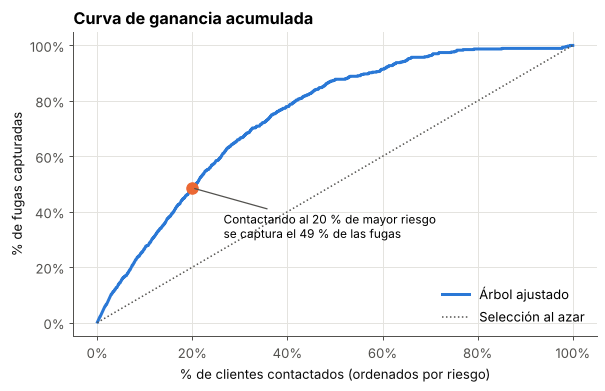

In [20]:
# Curva de ganancia acumulada (cumulative gains): ¿qué % de las fugas capturo contactando al top X %?
orden = np.argsort(-prob_te)
capt = np.cumsum(y_test.values[orden]) / y_test.sum()
pct = np.arange(1, len(orden) + 1) / len(orden)
k20 = int(0.2 * len(orden)) - 1

fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.plot(pct, capt, color=AZUL, lw=2.4, label="Árbol ajustado")
ax.plot([0, 1], [0, 1], ":", color=TINTA2, lw=1.2, label="Selección al azar")
ax.plot(pct[k20], capt[k20], "o", color=NARANJA, ms=9)
ax.annotate(f"Contactando al 20 % de mayor riesgo\nse captura el {capt[k20]*100:.0f} % de las fugas",
            (pct[k20], capt[k20]), xytext=(25, -40), textcoords="offset points", fontsize=9.5,
            arrowprops=dict(arrowstyle="-", color=TINTA2))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlabel("% de clientes contactados (ordenados por riesgo)"); ax.set_ylabel("% de fugas capturadas")
ax.set_title("Curva de ganancia acumulada"); ax.legend(loc="lower right")
guardar("10_ganancia_acumulada")
print(f"Lift en el top 20 %: {capt[k20] / 0.2:.1f}x")

## 8. Segmentación de riesgo para el equipo comercial

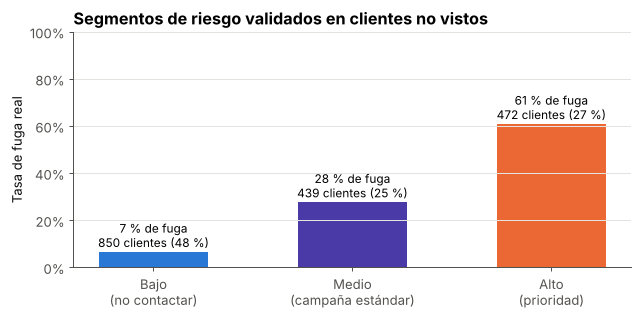

,clientes,churn_real,ingreso_mensual_fugado_usd,% de clientes
segmento,,,,
Bajo,850,0.067,2919.45,0.483
Medio,439,0.278,9299.40,0.249
Alto,472,0.610,22096.55,0.268


In [21]:
seg = pd.DataFrame({"prob": prob_te, "churn_real": y_test.values, "cargo": cargo_te}, index=X_test.index)
# Bajo: bajo el umbral óptimo (no conviene contactar) · Medio / Alto: dentro de la campaña
seg["segmento"] = pd.cut(seg["prob"], [-0.01, u_opt - 1e-9, 0.75, 1.0],
                         labels=["Bajo", "Medio", "Alto"])
resumen = seg.groupby("segmento", observed=True).agg(
    clientes=("prob", "size"), churn_real=("churn_real", "mean"),
    ingreso_mensual_fugado_usd=("cargo", lambda c: c[seg.loc[c.index, "churn_real"] == 1].sum()))
resumen["% de clientes"] = resumen["clientes"] / resumen["clientes"].sum()
resumen.to_csv(REP / "segmentos_riesgo.csv")

fig, ax = plt.subplots(figsize=(8, 3.4))
col_seg = {"Bajo": AZUL, "Medio": VIOLETA, "Alto": NARANJA}
barras = ax.bar(resumen.index.astype(str), resumen["churn_real"],
                color=[col_seg[s] for s in resumen.index.astype(str)], width=0.55)
for b, (_, r) in zip(barras, resumen.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02,
            f"{r['churn_real']*100:.0f} % de fuga\n{es(r['clientes'])} clientes ({r['% de clientes']*100:.0f} %)",
            ha="center", fontsize=9.5)
ax.set_xticks(range(3), ["Bajo\n(no contactar)", "Medio\n(campaña estándar)", "Alto\n(prioridad)"])
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_ylabel("Tasa de fuga real"); ax.grid(axis="x", visible=False)
ax.set_title("Segmentos de riesgo validados en clientes no vistos")
guardar("11_segmentos_riesgo")
resumen.round(3)

In [22]:
# Lista accionable: clientes de prueba en riesgo alto, ordenados por score e ingreso mensual.
# Nota: con class_weight="balanced" el score ordena bien el riesgo, pero NO es una probabilidad
# calibrada (está inflado hacia la clase minoritaria). Para probabilidades reales usar CalibratedClassifierCV.
lista = (df_original.loc[seg.index, ["customerID", "Contract", "tenure", "MonthlyCharges", "PaymentMethod"]]
         .assign(score_riesgo=seg["prob"].round(3), segmento=seg["segmento"])
         .query("segmento == 'Alto'").sort_values(["score_riesgo", "MonthlyCharges"], ascending=False))
lista.to_csv(REP / "clientes_prioritarios.csv", index=False)
joblib.dump(arbol, REP / "modelo_arbol_churn.joblib")
print(f"{len(lista)} clientes prioritarios exportados a reports/clientes_prioritarios.csv")
lista.head(10)

472 clientes prioritarios exportados a reports/clientes_prioritarios.csv


,customerID,Contract,tenure,MonthlyCharges,PaymentMethod,score_riesgo,segmento
2927,5542-TBBWB,Month-to-month,1,69.90,Electronic check,1.0,Alto
1739,9804-ICWBG,Month-to-month,1,69.90,Electronic check,1.0,Alto
5573,5550-VFRLC,Month-to-month,1,69.85,Electronic check,1.0,Alto
2084,1084-UQCHV,Month-to-month,1,69.75,Bank transfer (automatic),1.0,Alto
2607,5539-TMZLF,Month-to-month,1,69.75,Electronic check,1.0,Alto
6495,7254-IQWOZ,Month-to-month,1,69.65,Electronic check,1.0,Alto
1731,8375-DKEBR,Month-to-month,1,69.60,Electronic check,1.0,Alto
809,1820-TQVEV,Month-to-month,1,69.55,Electronic check,1.0,Alto
6488,0488-GSLFR,Month-to-month,1,69.50,Electronic check,1.0,Alto
2517,5186-SAMNZ,Month-to-month,1,69.50,Bank transfer (automatic),1.0,Alto


## 9. Conclusiones y recomendaciones

**Hallazgos clave**
1. **El contrato es el factor más importante.** Los clientes mes a mes concentran casi toda la fuga; el árbol los separa en su primera división.
2. **La antigüedad y el tipo de internet completan el perfil de riesgo:** clientes nuevos con fibra óptica y sin servicios de soporte son el segmento más vulnerable.
3. **Un árbol podado es casi tan bueno como modelos de caja negra**, y a cambio entrega reglas que cualquier ejecutivo comercial puede leer.
4. **El umbral importa más que el modelo:** elegir el punto de corte por beneficio y no por defecto (0,5) cambia el resultado económico de la campaña.

**Recomendaciones al negocio**
- Ofrecer incentivos para **migrar de contrato mensual a anual** durante los primeros 6 meses.
- Incluir **soporte técnico / seguridad online** en planes de fibra óptica como herramienta de retención.
- Promover el **pago automático** (tarjeta o transferencia) frente al cheque electrónico.
- Usar la lista de `reports/clientes_prioritarios.csv` como base para la campaña mensual.

**Limitaciones y próximos pasos**
- Los supuestos económicos son ilustrativos: deben calibrarse con datos reales de campañas (idealmente con un test A/B).
- El dataset es una foto en el tiempo; un modelo en producción necesita monitoreo de deriva de datos.
- Explorar modelos de *uplift* para identificar a quién **cambia** la oferta, no sólo a quién está en riesgo.